### all parameter combinations used:

- cluster_selection_epsilon = 0.0  
  - min_cluster_size = 25, 50, 75, 100  
    - min_samples = 3, 5, 10  
      - fraud_threshold = 0.05, 0.1, 0.15, 0.2  

- cluster_selection_epsilon = 0.25  
  - min_cluster_size = 25, 50, 75, 100  
    - min_samples = 3, 5, 10  
      - fraud_threshold = 0.05, 0.1, 0.15, 0.2  

- cluster_selection_epsilon = 0.5  
  - min_cluster_size = 25, 50, 75, 100  
    - min_samples = 3, 5, 10  
      - fraud_threshold = 0.05, 0.1, 0.15, 0.2  


### Best-found parameters (test set):

```
cluster_selection_epsilon = 0.0  
min_cluster_size = 50  
min_samples = 3  
fraud_threshold = 0.2  

Metrics:  
F1-score = 0.1064  
Recall = 0.6089  
Precision = 0.0583  
AUC = 0.7441
```

### Results is in `nb-v4-hdb.txt`

In [ ]:
import cudf
import cuml
import cupy as cp
import matplotlib.pyplot as plt
import seaborn as sns
from cuml.model_selection import train_test_split
from cuml.preprocessing import  OneHotEncoder, LabelEncoder, RobustScaler
from cuml.decomposition import PCA
from cuml.cluster import DBSCAN
from sklearn.metrics import (confusion_matrix, precision_score, 
                           recall_score, f1_score, accuracy_score,
                           roc_auc_score)
from sklearn.model_selection import ParameterGrid
import numpy as np
import warnings
import kagglehub
warnings.filterwarnings('ignore')

In [2]:
cuml.set_global_output_type('cupy')

In [3]:
def draw_confusion_matrix(cm, title='Confusion Matrix'):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Fraud', 'Fraud'], 
                yticklabels=['Not Fraud', 'Fraud'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [4]:
def print_confusion_matrix(cm, title):
    print(f"{title}:")
    print("         Predicted")
    print("         Not Fraud  Fraud")
    print("Actual")
    print(f"Not Fraud  {cm[0,0]:6d}  {cm[0,1]:6d}")
    print(f"Fraud      {cm[1,0]:6d}  {cm[1,1]:6d}")

In [5]:
def plot_pca_clusters(pca_df, title):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='PC1', y='PC2', hue='fraud', style='fraud', 
                    data=pca_df.to_pandas(), palette='viridis')
    plt.title(title)
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.show()

In [6]:
def load_and_preprocess_data():
    path = kagglehub.dataset_download("ealaxi/banksim1")
    data = cudf.read_csv(path + '/bs140513_032310.csv')
    
    data = data.drop(['zipcodeOri', 'zipMerchant'], axis=1)
    for col in ['customer', 'age', 'gender', 'merchant']:
        data[col] = data[col].str[1:-1]
    data['category'] = data['category'].str.replace('es_', '')
    data = data[data['gender'] != 'U']
    data['age'] = data['age'].replace('U', '7').astype('float32')
    data['amount'] = data['amount'].astype('float32')
    
    bins = [0, 500, 1000, 1500, 2000, 2500, 3000, float('inf')]
    labels = ['0-500', '500-1000', '1000-1500', '1500-2000', 
              '2000-2500', '2500-3000', '>3000']
    data['amount_thresh'] = cudf.cut(data['amount'], bins=bins, labels=labels)
    
    for entity in ['customer', 'merchant', 'category', 'amount_thresh']:
        freq = data.groupby(entity).size().reset_index(name=f'{entity}_freq')
        freq[f'{entity}_ID'] = cp.arange(1, len(freq) + 1)
        data = data.merge(freq, on=entity)
        if entity in ['customer', 'merchant']:
            data = data.drop(entity, axis=1)
        else:
            data[entity] = data[f'{entity}_ID']
            data = data.drop(f'{entity}_ID', axis=1)
    
    total = len(data)
    for col in data.columns:
        if '_freq' in col:
            data[col] = (data[col] / total * 100).round(5)
    
    ohe = OneHotEncoder(sparse=True, handle_unknown='ignore')
    ohe_cols = ['age', 'gender', 'category', 'amount_thresh']
    ohe_data = ohe.fit_transform(data[ohe_cols])
    ohe_data = cudf.DataFrame(ohe_data.toarray(), 
                             columns=ohe.get_feature_names(ohe_cols))
    data = cudf.concat([data.drop(ohe_cols, axis=1), ohe_data], axis=1)
    
    le = LabelEncoder()
    data['fraud'] = le.fit_transform(data['fraud'])
    
    return data

In [ ]:
from cuml.cluster import HDBSCAN   

def evaluate_hdbscan(params, X_train, y_train, X_test, y_test):
    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled  = scaler.transform(X_test)

    hdb = HDBSCAN(
        min_cluster_size=params['min_cluster_size'],
        min_samples=params['min_samples'],
        cluster_selection_epsilon=params.get('cluster_selection_epsilon', 0.0),
        gen_min_span_tree=False,
        output_type='cupy'
    )

    train_labels = hdb.fit_predict(X_train_scaled)
    test_labels  = hdb.fit_predict(X_test_scaled)

    def analyze_clusters(labels, true_labels):
        df = cudf.DataFrame({'cluster': labels, 'true_label': true_labels})
        stats = []
        for c in cp.unique(labels).get():
            if c == -1:               
                continue
            mask = df['cluster'] == c
            fraud_ratio = float(df[mask]['true_label'].mean())
            stats.append({'cluster': int(c),
                          'fraud_ratio': fraud_ratio,
                          'size': int(mask.sum())})
        return cudf.DataFrame(stats)

    train_stats = analyze_clusters(train_labels, y_train)
    cluster_mapping = {
        row.cluster: 1 if row.fraud_ratio > params['fraud_threshold'] else 0
        for row in train_stats.to_pandas().itertuples()
    }
    cluster_mapping[-1] = 0

    def evaluate(y_true, labels, name):
        pred = cudf.Series(labels).map(cluster_mapping).fillna(0)

        y_true_np = y_true.to_numpy() if hasattr(y_true, 'to_numpy') else np.asarray(y_true)
        y_pred_np = pred.to_numpy()
        cm = confusion_matrix(y_true_np, y_pred_np)
        print(f"\n=== {name} Results ===")
        print_confusion_matrix(cm, f"{name} Confusion Matrix")

        metrics = {
            'cm': cm,
            'recall': recall_score(y_true_np, y_pred_np),
            'precision': precision_score(y_true_np, y_pred_np),
            'f1': f1_score(y_true_np, y_pred_np),
            'accuracy': accuracy_score(y_true_np, y_pred_np),
            'auc': roc_auc_score(y_true_np, y_pred_np)
        }

        for k, v in metrics.items():
            if k != 'cm':
                print(f"{k.capitalize()}: {v:.4f}", end=' | ')
        print()
        return metrics
            
    return {
        'params': params,
        'train_metrics': evaluate(y_train, train_labels, "Training"),
        'test_metrics' : evaluate(y_test,  test_labels,  "Test"),
        'cluster_stats': train_stats,
        'model': hdb,
        'scaler': scaler
    }

In [ ]:
def main():
    data = load_and_preprocess_data()
    print("Data dimensions:", data.shape)
    
    pca_cols = [col for col in data.columns if col != 'fraud']
    scaler = RobustScaler()
    pca_data = PCA(n_components=2).fit_transform(scaler.fit_transform(data[pca_cols]))
    pca_df = cudf.DataFrame(pca_data, columns=['PC1', 'PC2'])
    pca_df['fraud'] = data['fraud']
    plot_pca_clusters(pca_df, 'Fraud Spread over Principal Components')
    
    X = data.drop('fraud', axis=1)
    y = data['fraud']
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=123, stratify=y)
    
    param_grid = {
    'cluster_selection_epsilon': [0.5],  
    'fraud_threshold' : [0.05, 0.10, 0.15, 0.20],
    'min_cluster_size': [25, 50, 75, 100],
    'min_samples'     : [3, 5, 10],
}
    
    results = []
    for params in ParameterGrid(param_grid):
        if params['fraud_threshold']==0.05:
            if not (params['min_cluster_size'] == 100 and params['min_samples'] == 10):
                continue
                
        print(f"\nEvaluating: {params}")
        result = evaluate_hdbscan(params, X_train, y_train, X_test, y_test)
        results.append(result)
    
    best_result = max(results, key=lambda x: x['test_metrics']['f1'])
    print("\n=== BEST MODEL ===")
    print(f"Parameters: "
          f"min_cluster_size={best_result['params']['min_cluster_size']}, "
          f"min_samples={best_result['params']['min_samples']}, "
          f"cluster_selection_epsilon={best_result['params']['cluster_selection_epsilon']}, "
          f"fraud_threshold={best_result['params']['fraud_threshold']}")
    print(f"Test F1: {best_result['test_metrics']['f1']:.4f} | ",
          f"Recall: {best_result['test_metrics']['recall']:.4f}")    
    return best_result


Data dimensions: (594076, 42)


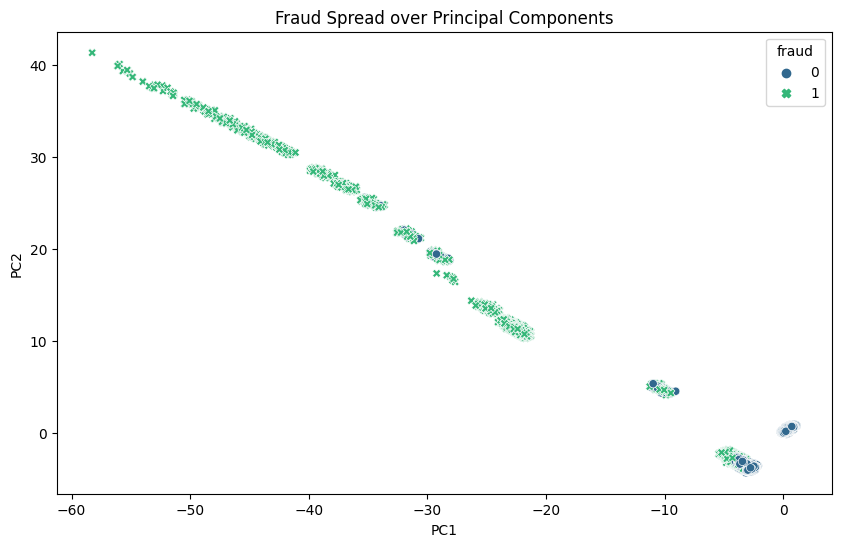


Evaluating: {'cluster_selection_epsilon': 0.5, 'fraud_threshold': 0.05, 'min_cluster_size': 100, 'min_samples': 10}

=== Training Results ===
Training Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud  428167   11990
Fraud        1204    4196
Recall: 0.7770 | Precision: 0.2592 | F1: 0.3888 | Accuracy: 0.9704 | Auc: 0.8749 | 

=== Test Results ===
Test Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud  113467   33252
Fraud        1165     635
Recall: 0.3528 | Precision: 0.0187 | F1: 0.0356 | Accuracy: 0.7683 | Auc: 0.5631 | 

Evaluating: {'cluster_selection_epsilon': 0.5, 'fraud_threshold': 0.1, 'min_cluster_size': 25, 'min_samples': 3}

=== Training Results ===
Training Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud  435205    4952
Fraud        1284    4116
Recall: 0.7622 | Precision: 0.4539 | F1: 0.5690 | Accuracy: 0.9860 | Auc: 0.8755 | 

=== Test Results ===
Test Confusion Matrix:
         

In [9]:
best_model = main()